# Experiment: FLUX.2 VAE ARC Palette Search

This Colab experiment asks whether the public ARC palette should remain the visual encoding for Diffusion-ARC or whether ten colors selected for RGB or frozen-VAE separation are more robust.

The white RGB value (255, 255, 255) remains the fixed PAD sentinel. A candidate qualifies only if it does not regress the clean VAE round-trip and improves both worst-case transformer-latent separation and robustness to controlled latent noise. The notebook does not change the project palette automatically.

## Colab prerequisites

1. Select an A100 GPU runtime.
2. Keep the complete FLUX.2 Klein Base snapshot at MyDrive/diffusion-arc/models/flux2-klein-base-4b.
3. Run the notebook from top to bottom and approve the single Drive mount prompt.

Only the Diffusers VAE subdirectory is loaded. Model downloads, FLUX generation, NVARC, task data, and training are outside this experiment.

In [ ]:
from __future__ import annotations

import importlib.metadata
import subprocess
import sys

PINNED_PACKAGES = {
    'diffusers': '0.39.0',
    'transformers': '4.56.1',
    'accelerate': '1.12.0',
    'safetensors': '0.8.0',
    'Pillow': '11.3.0',
}

requirements = []
for distribution, expected_version in PINNED_PACKAGES.items():
    try:
        installed_version = importlib.metadata.version(distribution)
    except importlib.metadata.PackageNotFoundError:
        installed_version = None
    if installed_version != expected_version:
        requirements.append(f'{distribution}=={expected_version}')

if requirements:
    print('Installing:', ' '.join(requirements))
    subprocess.run(
        [
            sys.executable,
            '-m',
            'pip',
            'install',
            '--quiet',
            '--no-cache-dir',
            '--upgrade-strategy',
            'only-if-needed',
            *requirements,
        ],
        check=True,
    )
else:
    print('All pinned experiment packages already match.')

{name: importlib.metadata.version(name) for name in PINNED_PACKAGES}


Installing: transformers==4.56.1 accelerate==1.12.0


{'diffusers': '0.39.0',
 'transformers': '4.56.1',
 'accelerate': '1.12.0',
 'safetensors': '0.8.0',
 'Pillow': '11.3.0'}

## Runtime and checkpoint

The VAE is copied from persistent Drive storage to the Colab VM once because repeated reads from local SSD are faster. Offline flags and local_files_only prevent accidental model downloads. The pinned weight hash must match before the experiment runs.

In [ ]:
import hashlib
import os
import shutil
from pathlib import Path

import numpy as np
import torch
from google.colab import drive

DRIVE_MOUNT = Path('/content/drive')
DRIVE_ROOT = DRIVE_MOUNT / 'MyDrive' / 'diffusion-arc'
MODEL_PATH = DRIVE_ROOT / 'models' / 'flux2-klein-base-4b'
VAE_SOURCE_PATH = MODEL_PATH / 'vae'
LOCAL_VAE_PATH = Path('/content/flux2-klein-base-4b-vae')
OUTPUT_DIR = DRIVE_ROOT / 'outputs' / 'vae-palette-experiment'
EXPECTED_VAE_SHA256 = 'ca70d2202afe6415bdbcb8793ba8cd99fd159cfe6192381504d6c4d3036e0f04'
GPU_INDEX = 0
COPY_VAE_TO_LOCAL_SSD = True

drive.mount(str(DRIVE_MOUNT), force_remount=False)
os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['TRANSFORMERS_OFFLINE'] = '1'

assert torch.cuda.is_available(), 'Select Runtime > Change runtime type > GPU.'
assert GPU_INDEX < torch.cuda.device_count()
torch.cuda.set_device(GPU_INDEX)
DEVICE = torch.device(f'cuda:{GPU_INDEX}')

required_files = ('config.json', 'diffusion_pytorch_model.safetensors')
missing_source = [name for name in required_files if not (VAE_SOURCE_PATH / name).is_file()]
assert not missing_source, f'Incomplete Drive VAE directory: {missing_source}'

if COPY_VAE_TO_LOCAL_SSD:
    if not LOCAL_VAE_PATH.exists():
        shutil.copytree(VAE_SOURCE_PATH, LOCAL_VAE_PATH)
    missing_local = [name for name in required_files if not (LOCAL_VAE_PATH / name).is_file()]
    assert not missing_local, f'Incomplete local VAE copy: {missing_local}'
    VAE_PATH = LOCAL_VAE_PATH
else:
    VAE_PATH = VAE_SOURCE_PATH

def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for chunk in iter(lambda: handle.read(8 * 1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

vae_weight_path = VAE_PATH / 'diffusion_pytorch_model.safetensors'
vae_sha256 = sha256_file(vae_weight_path)
assert vae_sha256 == EXPECTED_VAE_SHA256, (EXPECTED_VAE_SHA256, vae_sha256)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

gpu = torch.cuda.get_device_properties(GPU_INDEX)
runtime = {
    'gpu': gpu.name,
    'gpu_memory_GiB': round(gpu.total_memory / 2**30, 1),
    'torch': torch.__version__,
    'vae_path': str(VAE_PATH),
    'vae_sha256': vae_sha256,
    'output_dir': str(OUTPUT_DIR),
}
runtime


Mounted at /content/drive


{'gpu': 'NVIDIA A100-SXM4-40GB',
 'gpu_memory_GiB': 39.5,
 'torch': '2.11.0+cu128',
 'vae_path': '/content/flux2-klein-base-4b-vae',
 'vae_sha256': 'ca70d2202afe6415bdbcb8793ba8cd99fd159cfe6192381504d6c4d3036e0f04',
 'output_dir': '/content/drive/MyDrive/diffusion-arc/outputs/vae-palette-experiment'}

## Fixed experiment configuration

The VAE-aware search is deliberately discrete and inexpensive: it evaluates the 64 colors in a 4 by 4 by 4 RGB cube in multiple spatial contexts, then performs deterministic greedy maximin selection in the transformer-facing 128D latent space. This tests whether VAE-aware selection is promising before attempting continuous RGB optimization.

In [ ]:
SEED = 20260813
GRID_SIZE = 30
CELL_SIZE = 16
IMAGE_SIZE = GRID_SIZE * CELL_SIZE
PAD_CLASS = 10
PAD_RGB = (255, 255, 255)
CANDIDATE_LEVELS = (0, 85, 170, 255)
SEARCH_CONTEXT_MOSAICS = 4
EVALUATION_CONTEXT_MOSAICS = 4
NOISE_SIGMAS = (0.05, 0.10, 0.20, 0.35)

STANDARD_ARC_PALETTE = np.asarray(
    [
        (0x00, 0x00, 0x00),
        (0x00, 0x74, 0xD9),
        (0xFF, 0x41, 0x36),
        (0x2E, 0xCC, 0x40),
        (0xFF, 0xDC, 0x00),
        (0xAA, 0xAA, 0xAA),
        (0xF0, 0x12, 0xBE),
        (0xFF, 0x85, 0x1B),
        (0x7F, 0xDB, 0xFF),
        (0x87, 0x0C, 0x25),
        PAD_RGB,
    ],
    dtype=np.uint8,
)

np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
assert STANDARD_ARC_PALETTE.shape == (11, 3)
assert tuple(STANDARD_ARC_PALETTE[PAD_CLASS]) == PAD_RGB

{
    'seed': SEED,
    'image_size': IMAGE_SIZE,
    'candidate_levels': CANDIDATE_LEVELS,
    'candidate_count': len(CANDIDATE_LEVELS) ** 3,
    'noise_sigmas': NOISE_SIGMAS,
}


{'seed': 20260813,
 'image_size': 480,
 'candidate_levels': (0, 85, 170, 255),
 'candidate_count': 64,
 'noise_sigmas': (0.05, 0.1, 0.2, 0.35)}

In [ ]:
from diffusers import AutoencoderKLFlux2

vae = AutoencoderKLFlux2.from_pretrained(
    VAE_PATH,
    torch_dtype=torch.float32,
    local_files_only=True,
    low_cpu_mem_usage=False,
)
vae.eval()
vae.requires_grad_(False)
vae.to(DEVICE)

assert not vae.training
assert not any(parameter.requires_grad for parameter in vae.parameters())
assert next(vae.parameters()).dtype == torch.float32
assert vae.config.latent_channels == 32

{
    'class': type(vae).__name__,
    'parameters': sum(parameter.numel() for parameter in vae.parameters()),
    'dtype': str(next(vae.parameters()).dtype),
    'frozen': not any(parameter.requires_grad for parameter in vae.parameters()),
}


Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


{'class': 'AutoencoderKLFlux2',
 'parameters': 84046115,
 'dtype': 'torch.float32',
 'frozen': True}

## VAE and palette helpers

Every 480 by 480 image becomes a 60 by 60 VAE latent and then a normalized 128 by 30 by 30 transformer-facing latent. Consequently each ARC cell has exactly one 128D spatial token. Posterior mode is used throughout so encoding is deterministic.

In [ ]:
def synchronize() -> None:
    torch.cuda.synchronize(GPU_INDEX)

def patchify_latents(latents: torch.Tensor) -> torch.Tensor:
    batch, channels, height, width = latents.shape
    assert height % 2 == 0 and width % 2 == 0
    latents = latents.reshape(batch, channels, height // 2, 2, width // 2, 2)
    latents = latents.permute(0, 1, 3, 5, 2, 4)
    return latents.reshape(batch, channels * 4, height // 2, width // 2)

def unpatchify_latents(latents: torch.Tensor) -> torch.Tensor:
    batch, channels, height, width = latents.shape
    assert channels % 4 == 0
    latents = latents.reshape(batch, channels // 4, 2, 2, height, width)
    latents = latents.permute(0, 1, 4, 2, 5, 3)
    return latents.reshape(batch, channels // 4, height * 2, width * 2)

def normalize_for_transformer(latents: torch.Tensor) -> torch.Tensor:
    patched = patchify_latents(latents)
    mean = vae.bn.running_mean.view(1, -1, 1, 1).to(patched)
    std = torch.sqrt(
        vae.bn.running_var.view(1, -1, 1, 1).to(patched)
        + vae.config.batch_norm_eps
    )
    return (patched - mean) / std

def denormalize_from_transformer(latents: torch.Tensor) -> torch.Tensor:
    mean = vae.bn.running_mean.view(1, -1, 1, 1).to(latents)
    std = torch.sqrt(
        vae.bn.running_var.view(1, -1, 1, 1).to(latents)
        + vae.config.batch_norm_eps
    )
    return unpatchify_latents(latents * std + mean)

def render_labels(labels: np.ndarray, palette: np.ndarray) -> np.ndarray:
    labels = np.asarray(labels, dtype=np.int64)
    assert labels.shape == (GRID_SIZE, GRID_SIZE)
    assert int(labels.min()) >= 0 and int(labels.max()) < len(palette)
    cell_rgb = palette[labels]
    return np.repeat(
        np.repeat(cell_rgb, CELL_SIZE, axis=0),
        CELL_SIZE,
        axis=1,
    ).astype(np.uint8)

def image_tensor(rgb: np.ndarray) -> torch.Tensor:
    rgb = np.asarray(rgb, dtype=np.uint8)
    if rgb.ndim == 3:
        rgb = rgb[None, ...]
    assert rgb.ndim == 4 and rgb.shape[1:] == (IMAGE_SIZE, IMAGE_SIZE, 3)
    tensor = torch.from_numpy(rgb.copy()).permute(0, 3, 1, 2)
    return tensor.to(device=DEVICE, dtype=torch.float32).div(127.5).sub(1.0)

def encode_rgb(rgb: np.ndarray) -> torch.Tensor:
    sample = image_tensor(rgb)
    with torch.inference_mode():
        posterior_mode = vae.encode(sample).latent_dist.mode()
        transformer_latent = normalize_for_transformer(posterior_mode)
    assert transformer_latent.shape[1:] == (128, GRID_SIZE, GRID_SIZE)
    assert bool(torch.isfinite(transformer_latent).all())
    return transformer_latent

def decode_transformer_latent(latent: torch.Tensor) -> np.ndarray:
    with torch.inference_mode():
        reconstruction = vae.decode(denormalize_from_transformer(latent)).sample
    assert bool(torch.isfinite(reconstruction).all())
    array = reconstruction.detach().float().cpu().permute(0, 2, 3, 1).numpy()
    return np.clip((array + 1.0) * 127.5, 0.0, 255.0).round().astype(np.uint8)

def classify_cells(rgb: np.ndarray, palette: np.ndarray) -> np.ndarray:
    rgb = np.asarray(rgb, dtype=np.float32)
    assert rgb.shape == (IMAGE_SIZE, IMAGE_SIZE, 3)
    cell_means = rgb.reshape(
        GRID_SIZE, CELL_SIZE, GRID_SIZE, CELL_SIZE, 3
    ).mean(axis=(1, 3))
    prototypes = palette.astype(np.float32)
    distances = ((cell_means[:, :, None, :] - prototypes[None, None]) ** 2).sum(axis=-1)
    return distances.argmin(axis=-1).astype(np.int64)

def balanced_mosaics(num_classes: int, count: int, seed: int) -> list[np.ndarray]:
    rng = np.random.default_rng(seed)
    base = np.resize(np.arange(num_classes, dtype=np.int64), GRID_SIZE * GRID_SIZE)
    mosaics = []
    for _ in range(count):
        labels = base.copy()
        rng.shuffle(labels)
        mosaics.append(labels.reshape(GRID_SIZE, GRID_SIZE))
    return mosaics

def latent_prototypes(
    mosaics: list[np.ndarray], palette: np.ndarray
) -> tuple[np.ndarray, np.ndarray]:
    samples = [[] for _ in range(len(palette))]
    for labels in mosaics:
        latent = encode_rgb(render_labels(labels, palette))[0]
        tokens = latent.permute(1, 2, 0).detach().float().cpu().numpy()
        for class_index in range(len(palette)):
            samples[class_index].append(tokens[labels == class_index])
    stacked = [np.concatenate(parts, axis=0) for parts in samples]
    prototypes = np.stack([values.mean(axis=0) for values in stacked])
    spreads = np.asarray(
        [
            np.linalg.norm(values - prototype, axis=1).mean()
            for values, prototype in zip(stacked, prototypes)
        ],
        dtype=np.float64,
    )
    return prototypes.astype(np.float64), spreads


## Construct the two candidate palettes

RGB-Maximin and VAE-Latent-Maximin use the same 64 candidate colors and the same deterministic greedy rule. The first color is farthest from white; every later color maximizes its minimum distance to white and all already selected colors. This is a controlled comparison of distance spaces, not a claim of global optimality.

In [ ]:
from itertools import product

CANDIDATE_RGB = np.asarray(
    list(product(CANDIDATE_LEVELS, repeat=3)),
    dtype=np.uint8,
)
white_matches = np.flatnonzero(np.all(CANDIDATE_RGB == np.asarray(PAD_RGB), axis=1))
assert len(white_matches) == 1
CANDIDATE_PAD_INDEX = int(white_matches[0])

def select_maximin(vectors: np.ndarray, pad_index: int, count: int = 10) -> tuple[int, ...]:
    vectors = np.asarray(vectors, dtype=np.float64)
    distances = np.linalg.norm(vectors[:, None, :] - vectors[None, :, :], axis=-1)
    selected = []
    available = [index for index in range(len(vectors)) if index != pad_index]
    for _ in range(count):
        references = [pad_index, *selected]
        scores = distances[np.ix_(available, references)].min(axis=1)
        chosen_position = int(np.argmax(scores))
        selected.append(available.pop(chosen_position))
    return tuple(selected)

candidate_mosaics = balanced_mosaics(
    len(CANDIDATE_RGB), SEARCH_CONTEXT_MOSAICS, SEED + 1
)
candidate_latent_prototypes, candidate_latent_spreads = latent_prototypes(
    candidate_mosaics, CANDIDATE_RGB
)

rgb_selected_indices = select_maximin(
    CANDIDATE_RGB.astype(np.float64) / 255.0,
    CANDIDATE_PAD_INDEX,
)
vae_selected_indices = select_maximin(
    candidate_latent_prototypes,
    CANDIDATE_PAD_INDEX,
)

def selected_palette(indices: tuple[int, ...]) -> np.ndarray:
    colors = CANDIDATE_RGB[np.asarray(indices)]
    return np.concatenate([colors, np.asarray([PAD_RGB], dtype=np.uint8)], axis=0)

PALETTES = {
    'standard_arc': STANDARD_ARC_PALETTE,
    'rgb_maximin': selected_palette(rgb_selected_indices),
    'vae_latent_maximin': selected_palette(vae_selected_indices),
}
for name, palette in PALETTES.items():
    assert palette.shape == (11, 3), name
    assert tuple(palette[PAD_CLASS]) == PAD_RGB, name
    assert len({tuple(color) for color in palette}) == 11, name

selection_summary = {
    'rgb_selected_indices': rgb_selected_indices,
    'vae_selected_indices': vae_selected_indices,
    'rgb_palette': PALETTES['rgb_maximin'].tolist(),
    'vae_palette': PALETTES['vae_latent_maximin'].tolist(),
    'candidate_mean_within_class_spread': float(candidate_latent_spreads.mean()),
}
selection_summary


{'rgb_selected_indices': (0, 7, 28, 49, 14, 35, 56, 42, 21, 2),
 'vae_selected_indices': (0, 12, 48, 19, 15, 60, 21, 54, 46, 16),
 'rgb_palette': [[0, 0, 0],
  [0, 85, 255],
  [85, 255, 0],
  [255, 0, 85],
  [0, 255, 170],
  [170, 0, 255],
  [255, 170, 0],
  [170, 170, 170],
  [85, 85, 85],
  [0, 0, 170],
  [255, 255, 255]],
 'vae_palette': [[0, 0, 0],
  [0, 255, 0],
  [255, 0, 0],
  [85, 0, 255],
  [0, 255, 255],
  [255, 255, 0],
  [85, 85, 85],
  [255, 85, 170],
  [170, 255, 170],
  [85, 0, 0],
  [255, 255, 255]],
 'candidate_mean_within_class_spread': 3.403025336563587}

## Visual inspection helpers

The following displays use only Pillow and IPython, so the notebook does not need Matplotlib, Pandas, Seaborn, or scikit-learn.

/tmp/ipykernel_755/2342459917.py:7: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(np.asarray(rgb, dtype=np.uint8), mode='RGB')


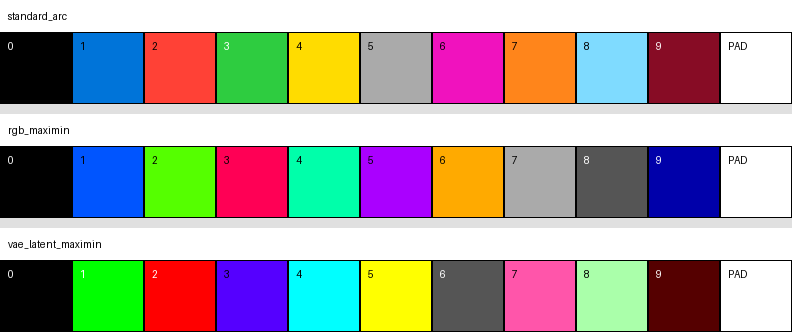

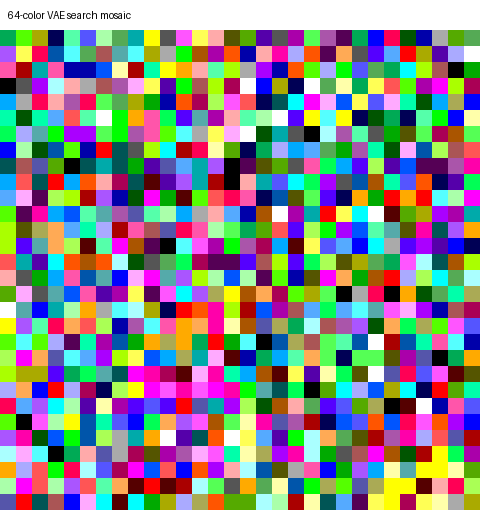

In [ ]:
import html
import math
from PIL import Image, ImageDraw
from IPython.display import HTML, display

def labeled_panel(rgb: np.ndarray, label: str, width: int = 220) -> Image.Image:
    image = Image.fromarray(np.asarray(rgb, dtype=np.uint8), mode='RGB')
    if image.width != width:
        height = round(image.height * width / image.width)
        image = image.resize((width, height), Image.Resampling.NEAREST)
    label_height = 30
    panel = Image.new('RGB', (image.width, image.height + label_height), 'white')
    panel.paste(image, (0, label_height))
    ImageDraw.Draw(panel).text((8, 9), label, fill='black')
    return panel

def join_images(images: list[Image.Image], columns: int, gap: int = 10) -> Image.Image:
    rows = math.ceil(len(images) / columns)
    cell_width = max(image.width for image in images)
    cell_height = max(image.height for image in images)
    canvas = Image.new(
        'RGB',
        (
            columns * cell_width + (columns - 1) * gap,
            rows * cell_height + (rows - 1) * gap,
        ),
        (224, 224, 224),
    )
    for index, image in enumerate(images):
        row, column = divmod(index, columns)
        canvas.paste(image, (column * (cell_width + gap), row * (cell_height + gap)))
    return canvas

def palette_panel(name: str, palette: np.ndarray) -> Image.Image:
    swatch_width = 72
    swatch_height = 72
    title_height = 32
    image = Image.new('RGB', (11 * swatch_width, title_height + swatch_height), 'white')
    draw = ImageDraw.Draw(image)
    draw.text((8, 10), name, fill='black')
    for index, color in enumerate(palette):
        left = index * swatch_width
        draw.rectangle(
            (left, title_height, left + swatch_width - 1, title_height + swatch_height - 1),
            fill=tuple(int(value) for value in color),
            outline='black',
        )
        luminance = float(np.mean(color))
        text_color = 'white' if luminance < 110 else 'black'
        label = 'PAD' if index == PAD_CLASS else str(index)
        draw.text((left + 8, title_height + 8), label, fill=text_color)
    return image

def html_table(rows: list[dict[str, object]], columns: list[str]) -> HTML:
    header = ''.join(f'<th>{html.escape(column)}</th>' for column in columns)
    body = []
    for row in rows:
        cells = ''.join(
            f'<td>{html.escape(str(row.get(column, "")))}</td>' for column in columns
        )
        body.append(f'<tr>{cells}</tr>')
    return HTML(
        '<table style="border-collapse:collapse" border="1" cellpadding="6">'
        f'<thead><tr>{header}</tr></thead><tbody>{"".join(body)}</tbody></table>'
    )

palette_image = join_images(
    [palette_panel(name, palette) for name, palette in PALETTES.items()],
    columns=1,
)
candidate_image = labeled_panel(
    render_labels(candidate_mosaics[0], CANDIDATE_RGB),
    '64-color VAE search mosaic',
    width=480,
)
display(palette_image)
display(candidate_image)


## Clean VAE round-trip and latent separation

All palettes see the same six synthetic class layouts. They cover color bands, isolated cells on PAD, thin lines, dense boundaries, balanced random contexts, and a smaller top-left grid surrounded by PAD. Latent prototypes are measured separately in identical balanced class mosaics.

In [ ]:
def make_patterns() -> dict[str, np.ndarray]:
    rows = np.arange(GRID_SIZE)[:, None]
    columns = np.arange(GRID_SIZE)[None, :]

    palette_bands = np.broadcast_to(
        columns * 11 // GRID_SIZE,
        (GRID_SIZE, GRID_SIZE),
    ).copy()

    isolated_cells = np.full((GRID_SIZE, GRID_SIZE), PAD_CLASS, dtype=np.int64)
    positions = ((2, 2), (2, 14), (2, 27), (8, 8), (8, 21), (14, 2), (14, 14), (14, 27), (21, 8), (27, 14))
    for color, (row, column) in enumerate(positions):
        isolated_cells[row, column] = color

    thin_lines = np.full((GRID_SIZE, GRID_SIZE), PAD_CLASS, dtype=np.int64)
    for color in range(10):
        coordinate = 1 + 3 * color
        thin_lines[coordinate, :] = color
        thin_lines[:, coordinate] = color

    checkerboard = ((rows * 3 + columns * 7) % 10).astype(np.int64)

    rng = np.random.default_rng(SEED + 100)
    random_balanced = rng.permutation(
        np.resize(np.arange(11, dtype=np.int64), GRID_SIZE * GRID_SIZE)
    ).reshape(GRID_SIZE, GRID_SIZE)

    top_left_small = np.full((GRID_SIZE, GRID_SIZE), PAD_CLASS, dtype=np.int64)
    top_left_small[:12, :17] = rng.integers(0, 10, size=(12, 17), dtype=np.int64)

    return {
        'palette_bands': palette_bands,
        'isolated_cells': isolated_cells,
        'thin_lines': thin_lines,
        'checkerboard': checkerboard,
        'random_balanced': random_balanced,
        'top_left_small': top_left_small,
    }

def confusion_metrics(matrix: np.ndarray) -> dict[str, float]:
    correct = int(np.trace(matrix))
    total = int(matrix.sum())
    pad_true_positive = int(matrix[PAD_CLASS, PAD_CLASS])
    predicted_pad = int(matrix[:, PAD_CLASS].sum())
    expected_pad = int(matrix[PAD_CLASS, :].sum())
    return {
        'cell_accuracy': correct / total,
        'pad_precision': pad_true_positive / max(1, predicted_pad),
        'pad_recall': pad_true_positive / max(1, expected_pad),
    }

def evaluate_palette(
    palette: np.ndarray, patterns: dict[str, np.ndarray]
) -> tuple[dict[str, object], dict[str, dict[str, object]]]:
    matrix = np.zeros((11, 11), dtype=np.int64)
    details = {}
    exact_grids = 0
    pixel_mae = []
    for pattern_name, expected in patterns.items():
        input_rgb = render_labels(expected, palette)
        latent = encode_rgb(input_rgb)
        reconstruction_rgb = decode_transformer_latent(latent)[0]
        predicted = classify_cells(reconstruction_rgb, palette)
        np.add.at(matrix, (expected.ravel(), predicted.ravel()), 1)
        exact = bool(np.array_equal(expected, predicted))
        exact_grids += int(exact)
        pixel_mae.append(
            float(
                np.abs(input_rgb.astype(np.float32) - reconstruction_rgb.astype(np.float32)).mean()
                / 255.0
            )
        )
        details[pattern_name] = {
            'expected': expected,
            'input_rgb': input_rgb,
            'reconstruction_rgb': reconstruction_rgb,
            'predicted': predicted,
            'latent': latent.detach().float().cpu(),
            'exact_grid': exact,
        }
        torch.cuda.empty_cache()
    summary = {
        **confusion_metrics(matrix),
        'exact_grids': exact_grids,
        'total_grids': len(patterns),
        'mean_pixel_mae': float(np.mean(pixel_mae)),
        'confusion_matrix': matrix.tolist(),
    }
    return summary, details

def separation_metrics(
    prototypes: np.ndarray, spreads: np.ndarray
) -> dict[str, float]:
    distances = np.linalg.norm(
        prototypes[:, None, :] - prototypes[None, :, :],
        axis=-1,
    )
    class_distances = distances[:10, :10]
    class_mask = ~np.eye(10, dtype=bool)
    inter_class = class_distances[class_mask]
    pad_distances = distances[:10, PAD_CLASS]
    worst_margin = min(float(inter_class.min()), float(pad_distances.min()))
    mean_spread = float(spreads.mean())
    return {
        'minimum_class_distance': float(inter_class.min()),
        'mean_class_distance': float(inter_class.mean()),
        'minimum_pad_distance': float(pad_distances.min()),
        'mean_within_class_spread': mean_spread,
        'worst_margin_over_spread': worst_margin / max(mean_spread, 1e-12),
    }

PATTERNS = make_patterns()
class_context_mosaics = balanced_mosaics(11, EVALUATION_CONTEXT_MOSAICS, SEED + 200)
clean_summaries = {}
clean_details = {}
latent_summaries = {}
latent_details = {}

for palette_name, palette in PALETTES.items():
    print('Evaluating:', palette_name)
    clean_summaries[palette_name], clean_details[palette_name] = evaluate_palette(
        palette, PATTERNS
    )
    prototypes, spreads = latent_prototypes(class_context_mosaics, palette)
    latent_summaries[palette_name] = separation_metrics(prototypes, spreads)
    latent_details[palette_name] = {
        'prototypes': prototypes,
        'spreads': spreads,
    }
    torch.cuda.empty_cache()

clean_rows = []
for palette_name in PALETTES:
    clean = clean_summaries[palette_name]
    latent = latent_summaries[palette_name]
    clean_rows.append(
        {
            'palette': palette_name,
            'cell accuracy': f'{clean["cell_accuracy"]:.6f}',
            'exact grids': f'{clean["exact_grids"]}/{clean["total_grids"]}',
            'PAD precision': f'{clean["pad_precision"]:.6f}',
            'PAD recall': f'{clean["pad_recall"]:.6f}',
            'min class distance': f'{latent["minimum_class_distance"]:.4f}',
            'min PAD distance': f'{latent["minimum_pad_distance"]:.4f}',
            'margin / spread': f'{latent["worst_margin_over_spread"]:.4f}',
        }
    )

display(html_table(clean_rows, list(clean_rows[0])))


Evaluating: standard_arc
Evaluating: rgb_maximin
Evaluating: vae_latent_maximin


palette,cell accuracy,exact grids,PAD precision,PAD recall,min class distance,min PAD distance,margin / spread
standard_arc,1.000000,6/6,1.000000,1.000000,3.0054,5.9972,0.8211
rgb_maximin,1.000000,6/6,1.000000,1.000000,3.9333,5.9623,1.0832
vae_latent_maximin,1.000000,6/6,1.000000,1.000000,5.1209,5.4031,1.4111


/tmp/ipykernel_755/2342459917.py:7: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(np.asarray(rgb, dtype=np.uint8), mode='RGB')


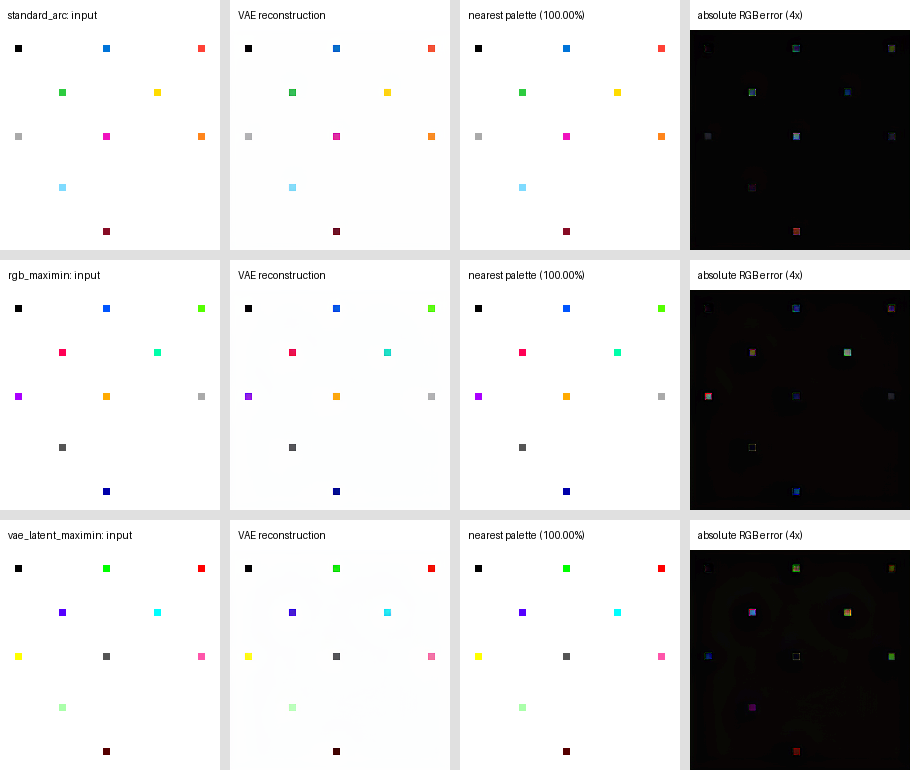

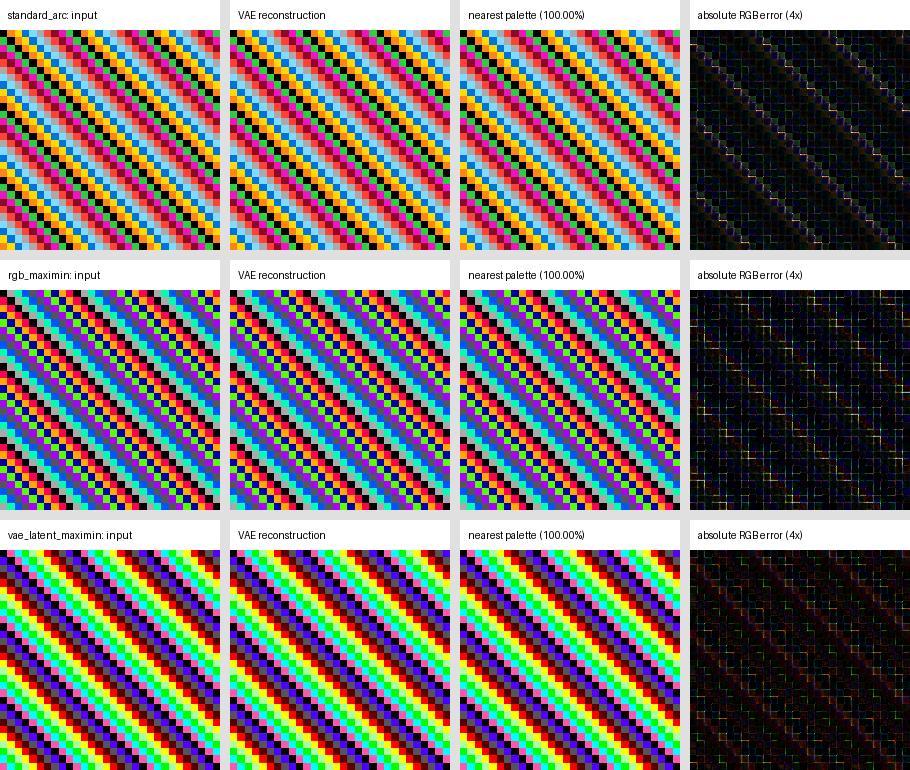

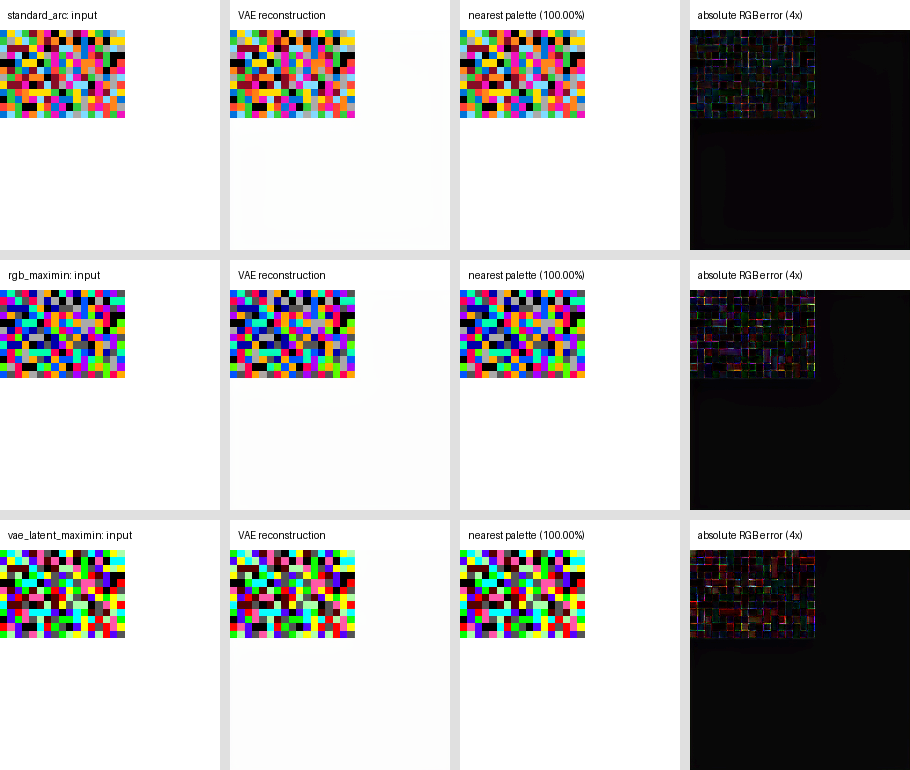

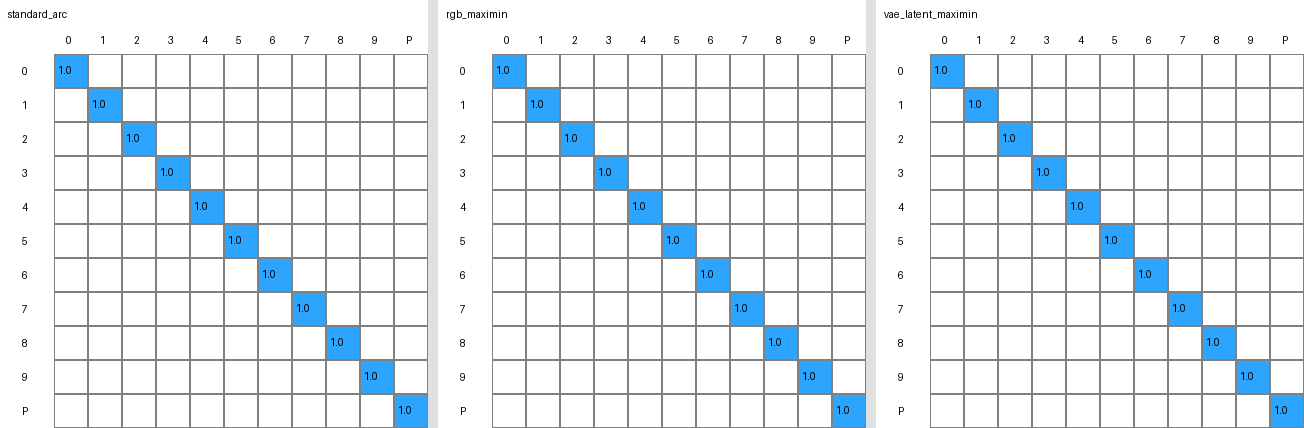

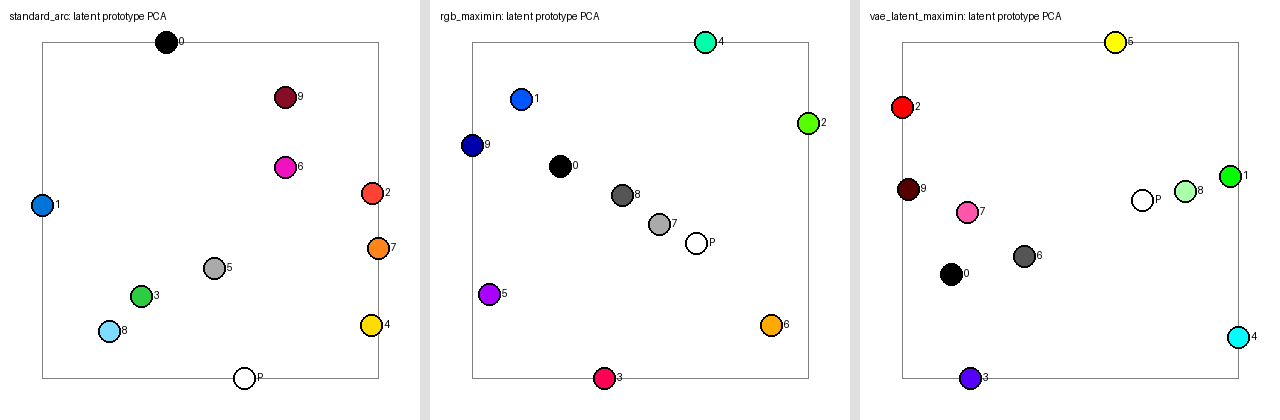

In [ ]:
def amplified_difference(input_rgb: np.ndarray, reconstruction_rgb: np.ndarray) -> np.ndarray:
    difference = np.abs(
        input_rgb.astype(np.int16) - reconstruction_rgb.astype(np.int16)
    )
    return np.clip(difference * 4, 0, 255).astype(np.uint8)

def reconstruction_overview(pattern_name: str) -> Image.Image:
    panels = []
    for palette_name, palette in PALETTES.items():
        detail = clean_details[palette_name][pattern_name]
        accuracy = float(
            np.mean(detail['expected'] == detail['predicted'])
        )
        panels.extend(
            [
                labeled_panel(detail['input_rgb'], f'{palette_name}: input'),
                labeled_panel(detail['reconstruction_rgb'], 'VAE reconstruction'),
                labeled_panel(
                    render_labels(detail['predicted'], palette),
                    f'nearest palette ({accuracy:.2%})',
                ),
                labeled_panel(
                    amplified_difference(detail['input_rgb'], detail['reconstruction_rgb']),
                    'absolute RGB error (4x)',
                ),
            ]
        )
    return join_images(panels, columns=4)

def confusion_heatmap(matrix: np.ndarray, title: str) -> Image.Image:
    matrix = np.asarray(matrix, dtype=np.float64)
    normalized = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1.0)
    cell = 34
    margin = 54
    image = Image.new('RGB', (margin + 11 * cell, margin + 11 * cell), 'white')
    draw = ImageDraw.Draw(image)
    draw.text((8, 8), title, fill='black')
    for index in range(11):
        label = 'P' if index == PAD_CLASS else str(index)
        draw.text((margin + index * cell + 12, 34), label, fill='black')
        draw.text((22, margin + index * cell + 11), label, fill='black')
    for row in range(11):
        for column in range(11):
            value = float(normalized[row, column])
            color = (255 - round(210 * value), 255 - round(90 * value), 255)
            left = margin + column * cell
            top = margin + row * cell
            draw.rectangle((left, top, left + cell - 1, top + cell - 1), fill=color, outline='gray')
            if value > 0:
                draw.text((left + 4, top + 10), f'{value:.1f}', fill='black')
    return image

def latent_scatter(name: str, palette: np.ndarray, prototypes: np.ndarray) -> Image.Image:
    centered = prototypes - prototypes.mean(axis=0, keepdims=True)
    _, _, right = np.linalg.svd(centered, full_matrices=False)
    points = centered @ right[:2].T
    low = points.min(axis=0)
    high = points.max(axis=0)
    scaled = (points - low) / np.maximum(high - low, 1e-12)
    size = 420
    margin = 42
    image = Image.new('RGB', (size, size), 'white')
    draw = ImageDraw.Draw(image)
    draw.text((10, 10), f'{name}: latent prototype PCA', fill='black')
    draw.rectangle((margin, margin, size - margin, size - margin), outline='gray')
    for index, point in enumerate(scaled):
        x = margin + int(point[0] * (size - 2 * margin))
        y = size - margin - int(point[1] * (size - 2 * margin))
        radius = 11
        fill = tuple(int(value) for value in palette[index])
        draw.ellipse((x - radius, y - radius, x + radius, y + radius), fill=fill, outline='black', width=2)
        label = 'P' if index == PAD_CLASS else str(index)
        draw.text((x + 13, y - 7), label, fill='black')
    return image

for pattern_name in ('isolated_cells', 'checkerboard', 'top_left_small'):
    overview = reconstruction_overview(pattern_name)
    overview.save(OUTPUT_DIR / f'{pattern_name}-overview.png')
    display(overview)

confusions = join_images(
    [
        confusion_heatmap(
            np.asarray(clean_summaries[name]['confusion_matrix']), name
        )
        for name in PALETTES
    ],
    columns=3,
)
latent_plot = join_images(
    [
        latent_scatter(name, PALETTES[name], latent_details[name]['prototypes'])
        for name in PALETTES
    ],
    columns=3,
)
display(confusions)
display(latent_plot)


## Robustness to transformer-latent noise

The normalized transformer latents are perturbed with shared standard-normal noise at fixed sigma values. Resetting the generator for every palette ensures that corresponding patterns receive the same noise realization. This is a diagnostic proxy for imperfect FLUX predictions, not a replacement for the later trained-FLUX A/B test.

In [ ]:
noise_summaries = {}
for palette_index, (palette_name, palette) in enumerate(PALETTES.items()):
    rows = [
        {
            'sigma': 0.0,
            'cell_accuracy': float(clean_summaries[palette_name]['cell_accuracy']),
            'exact_grids': int(clean_summaries[palette_name]['exact_grids']),
            'pad_precision': float(clean_summaries[palette_name]['pad_precision']),
            'pad_recall': float(clean_summaries[palette_name]['pad_recall']),
        }
    ]
    for sigma_index, sigma in enumerate(NOISE_SIGMAS):
        matrix = np.zeros((11, 11), dtype=np.int64)
        exact_grids = 0
        for pattern_index, (pattern_name, expected) in enumerate(PATTERNS.items()):
            latent = clean_details[palette_name][pattern_name]['latent'].to(DEVICE)
            noise_seed = SEED + 10_000 + sigma_index * 100 + pattern_index
            generator = torch.Generator(device=DEVICE).manual_seed(noise_seed)
            noise = torch.randn(
                latent.shape,
                generator=generator,
                device=DEVICE,
                dtype=latent.dtype,
            )
            reconstruction = decode_transformer_latent(latent + sigma * noise)[0]
            predicted = classify_cells(reconstruction, palette)
            np.add.at(matrix, (expected.ravel(), predicted.ravel()), 1)
            exact_grids += int(np.array_equal(expected, predicted))
        metrics = confusion_metrics(matrix)
        rows.append(
            {
                'sigma': float(sigma),
                'cell_accuracy': metrics['cell_accuracy'],
                'exact_grids': exact_grids,
                'pad_precision': metrics['pad_precision'],
                'pad_recall': metrics['pad_recall'],
            }
        )
        torch.cuda.empty_cache()
    noise_summaries[palette_name] = rows

robustness_rows = []
for palette_name, rows in noise_summaries.items():
    for row in rows:
        robustness_rows.append(
            {
                'palette': palette_name,
                'sigma': f'{row["sigma"]:.2f}',
                'cell accuracy': f'{row["cell_accuracy"]:.6f}',
                'exact grids': f'{row["exact_grids"]}/{len(PATTERNS)}',
                'PAD precision': f'{row["pad_precision"]:.6f}',
                'PAD recall': f'{row["pad_recall"]:.6f}',
            }
        )

display(html_table(robustness_rows, list(robustness_rows[0])))


palette,sigma,cell accuracy,exact grids,PAD precision,PAD recall
standard_arc,0.00,1.000000,6/6,1.000000,1.000000
standard_arc,0.05,1.000000,6/6,1.000000,1.000000
standard_arc,0.10,1.000000,6/6,1.000000,1.000000
standard_arc,0.20,1.000000,6/6,1.000000,1.000000
standard_arc,0.35,1.000000,6/6,1.000000,1.000000
rgb_maximin,0.00,1.000000,6/6,1.000000,1.000000
rgb_maximin,0.05,1.000000,6/6,1.000000,1.000000
rgb_maximin,0.10,1.000000,6/6,1.000000,1.000000
rgb_maximin,0.20,1.000000,6/6,1.000000,1.000000
rgb_maximin,0.35,1.000000,6/6,1.000000,1.000000


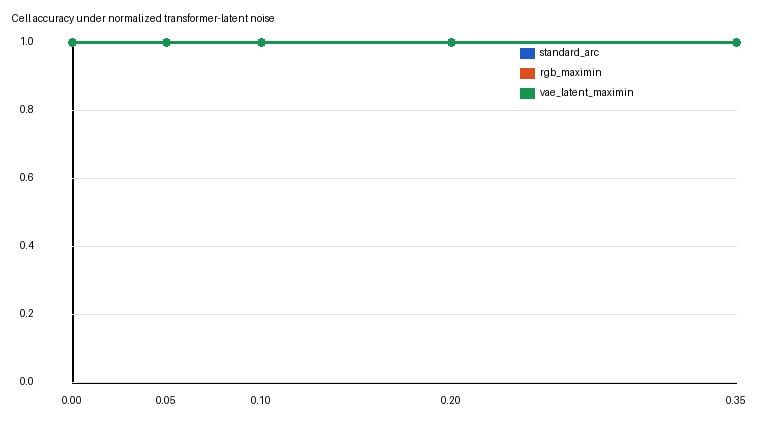

{'rgb_maximin': {'clean_not_worse': True,
  'latent_worst_case_better': True,
  'mean_noise_accuracy': 1.0,
  'mean_noise_accuracy_better': False,
  'qualifies_for_flux_ab_test': False},
 'vae_latent_maximin': {'clean_not_worse': True,
  'latent_worst_case_better': True,
  'mean_noise_accuracy': 1.0,
  'mean_noise_accuracy_better': False,
  'qualifies_for_flux_ab_test': False}}

In [ ]:
def robustness_plot(results: dict[str, list[dict[str, float]]]) -> Image.Image:
    width = 760
    height = 440
    left, right, top, bottom = 72, 24, 42, 58
    image = Image.new('RGB', (width, height), 'white')
    draw = ImageDraw.Draw(image)
    draw.text((12, 12), 'Cell accuracy under normalized transformer-latent noise', fill='black')
    draw.line((left, top, left, height - bottom), fill='black', width=2)
    draw.line((left, height - bottom, width - right, height - bottom), fill='black', width=2)
    colors = {
        'standard_arc': (30, 90, 200),
        'rgb_maximin': (220, 80, 30),
        'vae_latent_maximin': (20, 150, 80),
    }
    all_sigmas = [row['sigma'] for rows in results.values() for row in rows]
    max_sigma = max(all_sigmas)
    for tick in np.linspace(0.0, 1.0, 6):
        y = height - bottom - int(tick * (height - top - bottom))
        draw.line((left, y, width - right, y), fill=(225, 225, 225))
        draw.text((20, y - 7), f'{tick:.1f}', fill='black')
    for palette_name, rows in results.items():
        points = []
        for row in rows:
            x = left + int(row['sigma'] / max_sigma * (width - left - right))
            y = height - bottom - int(row['cell_accuracy'] * (height - top - bottom))
            points.append((x, y))
        draw.line(points, fill=colors[palette_name], width=3)
        for point in points:
            draw.ellipse((point[0] - 4, point[1] - 4, point[0] + 4, point[1] + 4), fill=colors[palette_name])
    legend_y = 48
    for palette_name, color in colors.items():
        draw.rectangle((width - 240, legend_y, width - 226, legend_y + 10), fill=color)
        draw.text((width - 220, legend_y - 2), palette_name, fill='black')
        legend_y += 20
    for sigma in sorted(set(all_sigmas)):
        x = left + int(sigma / max_sigma * (width - left - right))
        draw.text((x - 10, height - bottom + 12), f'{sigma:.2f}', fill='black')
    return image

robustness_image = robustness_plot(noise_summaries)
display(robustness_image)

baseline_name = 'standard_arc'
baseline_robustness = float(
    np.mean([row['cell_accuracy'] for row in noise_summaries[baseline_name][1:]])
)
decisions = {}
for candidate_name in ('rgb_maximin', 'vae_latent_maximin'):
    candidate_robustness = float(
        np.mean([row['cell_accuracy'] for row in noise_summaries[candidate_name][1:]])
    )
    clean_not_worse = (
        clean_summaries[candidate_name]['cell_accuracy']
        >= clean_summaries[baseline_name]['cell_accuracy']
        and clean_summaries[candidate_name]['exact_grids']
        >= clean_summaries[baseline_name]['exact_grids']
        and clean_summaries[candidate_name]['pad_recall']
        >= clean_summaries[baseline_name]['pad_recall']
    )
    latent_better = (
        min(
            latent_summaries[candidate_name]['minimum_class_distance'],
            latent_summaries[candidate_name]['minimum_pad_distance'],
        )
        > min(
            latent_summaries[baseline_name]['minimum_class_distance'],
            latent_summaries[baseline_name]['minimum_pad_distance'],
        )
    )
    robustness_better = candidate_robustness > baseline_robustness
    decisions[candidate_name] = {
        'clean_not_worse': bool(clean_not_worse),
        'latent_worst_case_better': bool(latent_better),
        'mean_noise_accuracy': candidate_robustness,
        'mean_noise_accuracy_better': bool(robustness_better),
        'qualifies_for_flux_ab_test': bool(
            clean_not_worse and latent_better and robustness_better
        ),
    }

decisions


## Save the reproducibility report

The report and visual panels are written to Drive, not to the repository. A qualifying candidate is only evidence for a later controlled FLUX overfitting A/B test; it is not sufficient evidence to replace the standard ARC palette.

In [ ]:
import json
from datetime import datetime, timezone

palette_image.save(OUTPUT_DIR / 'palettes.png')
candidate_image.save(OUTPUT_DIR / 'candidate-mosaic.png')
confusions.save(OUTPUT_DIR / 'clean-confusion-matrices.png')
latent_plot.save(OUTPUT_DIR / 'latent-prototype-pca.png')
robustness_image.save(OUTPUT_DIR / 'latent-noise-robustness.png')

report = {
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'runtime': runtime,
    'configuration': {
        'seed': SEED,
        'grid_size': GRID_SIZE,
        'cell_size': CELL_SIZE,
        'image_size': IMAGE_SIZE,
        'pad_class': PAD_CLASS,
        'pad_rgb': list(PAD_RGB),
        'candidate_levels': list(CANDIDATE_LEVELS),
        'search_context_mosaics': SEARCH_CONTEXT_MOSAICS,
        'evaluation_context_mosaics': EVALUATION_CONTEXT_MOSAICS,
        'noise_sigmas': list(NOISE_SIGMAS),
        'posterior_statistic': 'mode',
        'transformer_latent_shape': [128, 30, 30],
    },
    'palettes': {name: palette.tolist() for name, palette in PALETTES.items()},
    'selection': {
        'rgb_candidate_indices': list(rgb_selected_indices),
        'vae_candidate_indices': list(vae_selected_indices),
    },
    'clean_roundtrip': clean_summaries,
    'latent_separation': latent_summaries,
    'latent_noise': noise_summaries,
    'decision': decisions,
}

report_path = OUTPUT_DIR / 'metrics.json'
report_path.write_text(json.dumps(report, indent=2), encoding='utf-8')

{
    'report': str(report_path),
    'artifacts': sorted(path.name for path in OUTPUT_DIR.glob('*.png')),
    'decision': decisions,
}


{'report': '/content/drive/MyDrive/diffusion-arc/outputs/vae-palette-experiment/metrics.json',
 'artifacts': ['candidate-mosaic.png',
  'checkerboard-overview.png',
  'clean-confusion-matrices.png',
  'isolated_cells-overview.png',
  'latent-noise-robustness.png',
  'latent-prototype-pca.png',
  'palettes.png',
  'top_left_small-overview.png'],
 'decision': {'rgb_maximin': {'clean_not_worse': True,
   'latent_worst_case_better': True,
   'mean_noise_accuracy': 1.0,
   'mean_noise_accuracy_better': False,
   'qualifies_for_flux_ab_test': False},
  'vae_latent_maximin': {'clean_not_worse': True,
   'latent_worst_case_better': True,
   'mean_noise_accuracy': 1.0,
   'mean_noise_accuracy_better': False,
   'qualifies_for_flux_ab_test': False}}}

## Interpretation and next steps

- If neither candidate qualifies, keep the standard ARC palette and stop this branch of investigation.
- If RGB-Maximin qualifies but VAE-Latent-Maximin does not, raw color separation may be enough; repeat with more random contexts before any project change.
- If VAE-Latent-Maximin qualifies consistently, refine its coarse RGB candidates or test continuous optimization in a separate experiment.
- Before changing the project palette, compare the standard palette and the best candidate in the same tiny FLUX overfitting run with identical data, seeds, and compute.